In [2]:
import pandas as pd 
import matplotlib.pyplot as plt

#Load dataset
df = pd.read_csv("./Data/AR_MA_Sales_Dataset.csv")
#Convert Data to datetime 
df["Date"] = pd.to_datetime(df["Date"])
#Set index
df.set_index("Date",inplace=True)
print(df.head())

             Sales
Date              
2021-01-01  100.00
2021-02-01  102.48
2021-03-01  101.17
2021-04-01  104.12
2021-05-01  110.70


In [3]:
df['Sales_Lag1'] = df['Sales'].shift(1)
print(df[["Sales","Sales_Lag1"]].head(10))

             Sales  Sales_Lag1
Date                          
2021-01-01  100.00         NaN
2021-02-01  102.48      100.00
2021-03-01  101.17      102.48
2021-04-01  104.12      101.17
2021-05-01  110.70      104.12
2021-06-01  106.86      110.70
2021-07-01  103.97      106.86
2021-08-01  110.87      103.97
2021-09-01  111.99      110.87
2021-10-01  106.65      111.99


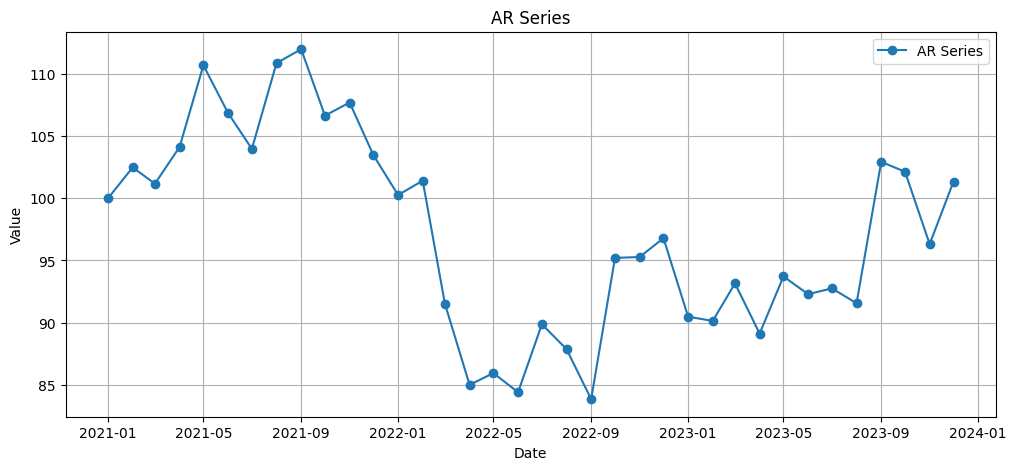

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df["Sales"],
    marker="o",
    label="AR Series"
)

plt.xlabel("Date")
plt.ylabel("Value")
plt.title("AR Series")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
from statsmodels.tsa.ar_model import AutoReg
#FIt AR(1)
#Create an Autoregressive (AR) model  
ar_model = AutoReg(
    #Specfy the tiume series that we wnat to model/forecast 
    df["Sales"],
    #Use 1 lag ->AR(1)
    lags=1,
    trend="c"
)
ar_result = ar_model.fit()

C:\Users\Rajguru\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [6]:
print("AR coeficient:")
print(ar_result.params)

AR coeficient:
const       17.298055
Sales.L1     0.822418
dtype: float64


In [7]:
len(df)

36

In [8]:
ar_forecast = ar_result.predict( #generate forecast using fitted AR model
    start=len(df),               #Start forecasting from the first position after the existing data
    end=len(df)+5                #End forecasting at position len(df)+5
)

C:\Users\Rajguru\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)


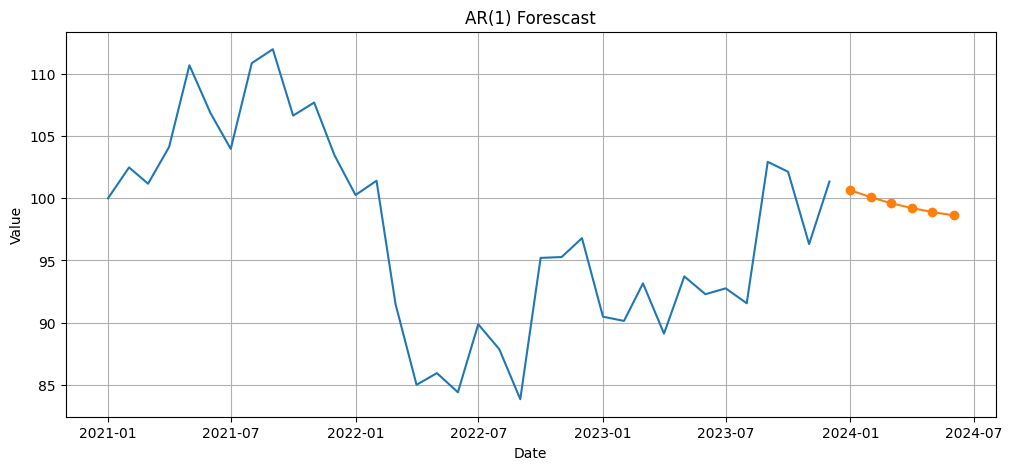

In [9]:
#Plot AR 
plt.figure(figsize=(12,5))

plt.plot(
    df.index,
    df["Sales"],
    label="Actual AR Series"
)
plt.plot(
    ar_forecast.index,
    ar_forecast,
    marker="o",
    label="AR(1) Forecast"
)

plt.title("AR(1) Forescast")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend
plt.grid(True)


In [10]:
from statsmodels.tsa.arima.model import ARIMA
sales = df['Sales']
ma_model = ARIMA(sales,
                 order = (0, 0, 1)
)

#Fit the MA model
ma_result = ma_model.fit()

C:\Users\Rajguru\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [11]:
#Forecast the next 5 months
ma_forecast = ma_result.forecast(steps=5)
#Display the forecasts
print(ma_forecast)

2024-01-01    98.034346
2024-02-01    97.343195
2024-03-01    97.343195
2024-04-01    97.343195
2024-05-01    97.343195
Freq: MS, Name: predicted_mean, dtype: float64


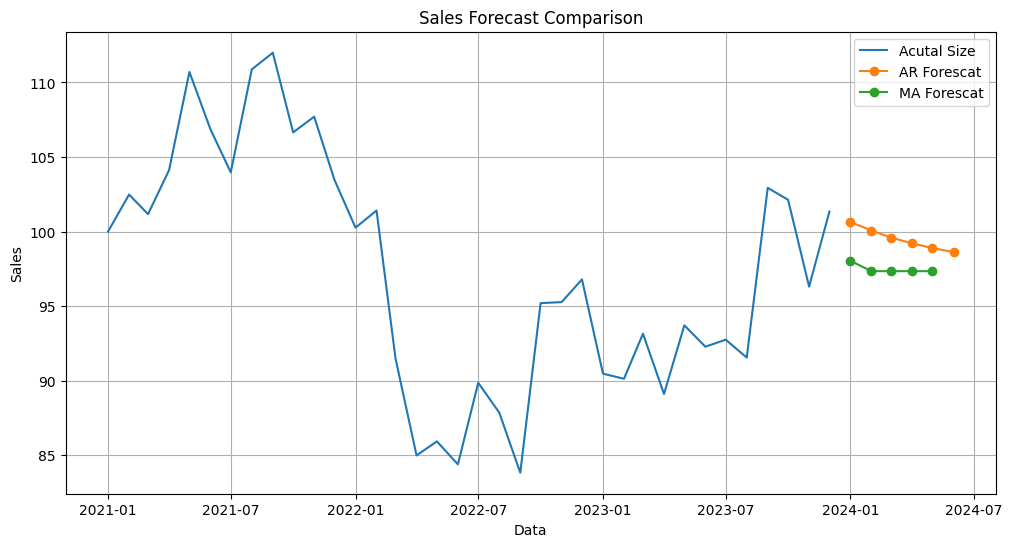

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

#Plot actual sales
plt.plot(df.index,df["Sales"],label="Acutal Size")
#Plot AR forecast 
plt.plot(ar_forecast.index,ar_forecast,
         marker="o", label="AR Forescat")
#Plot MA forecast
plt.plot(ma_forecast.index,ma_forecast,
         marker="o", label="MA Forescat")

plt.title("Sales Forecast Comparison")
plt.xlabel("Data")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
from statsmodels.tsa.arima.model import ARIMA
sales = df['Sales']
arima_model = ARIMA(sales,
                 order = (1, 1, 1)
)

#Fit the MA model
arima_result = arima_model.fit()

C:\Users\Rajguru\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [14]:
#Forecast the next 5 months
arima_forecast = arima_result.forecast(steps=5)
#Display the forecasts
print(ma_forecast)

2024-01-01    98.034346
2024-02-01    97.343195
2024-03-01    97.343195
2024-04-01    97.343195
2024-05-01    97.343195
Freq: MS, Name: predicted_mean, dtype: float64


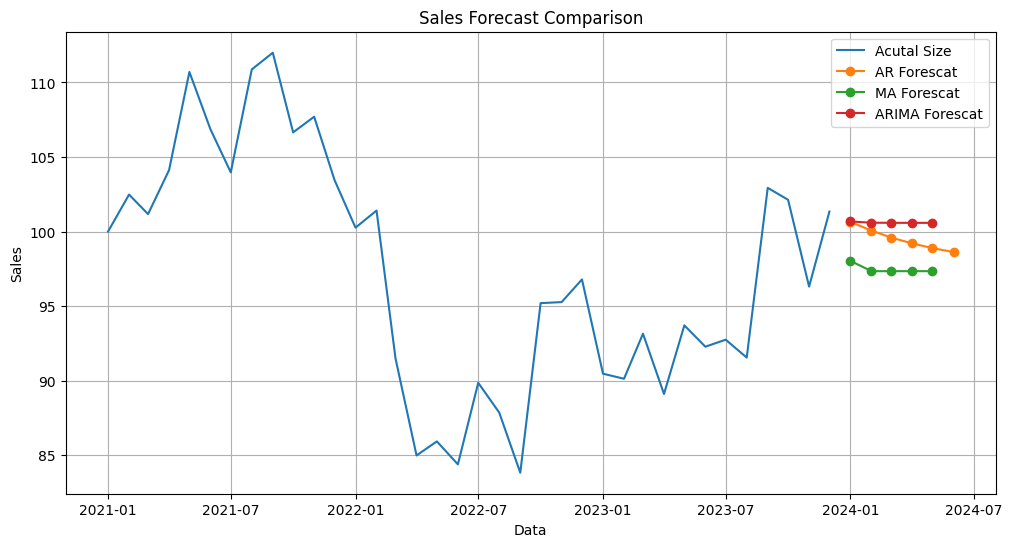

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

#Plot actual sales
plt.plot(df.index,df["Sales"],label="Acutal Size")
#Plot AR forecast 
plt.plot(ar_forecast.index,ar_forecast,
         marker="o", label="AR Forescat")
#Plot MA forecast
plt.plot(ma_forecast.index,ma_forecast,
         marker="o", label="MA Forescat")
plt.plot(arima_forecast.index,arima_forecast,
         marker="o", label="ARIMA Forescat")


plt.title("Sales Forecast Comparison")
plt.xlabel("Data")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
sales = df['Sales']
sarima_model = SARIMAX(
                sales,
                 order = (1, 1, 1),
                 seasonal_order = (1, 1, 1,12)
)

#Fit the MA model
sarima_result = sarima_model.fit()
sarima_forecast = sarima_result.forecast(steps=12)
print(sarima_forecast)

C:\Users\Rajguru\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Rajguru\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


2024-01-01    95.744798
2024-02-01    95.615276
2024-03-01    89.337990
2024-04-01    80.871070
2024-05-01    81.751158
2024-06-01    81.050073
2024-07-01    86.824885
2024-08-01    82.201627
2024-09-01    84.250345
2024-10-01    95.123676
2024-11-01    91.866276
2024-12-01    97.124288
Freq: MS, Name: predicted_mean, dtype: float64


C:\Users\Rajguru\AppData\Roaming\Python\Python313\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


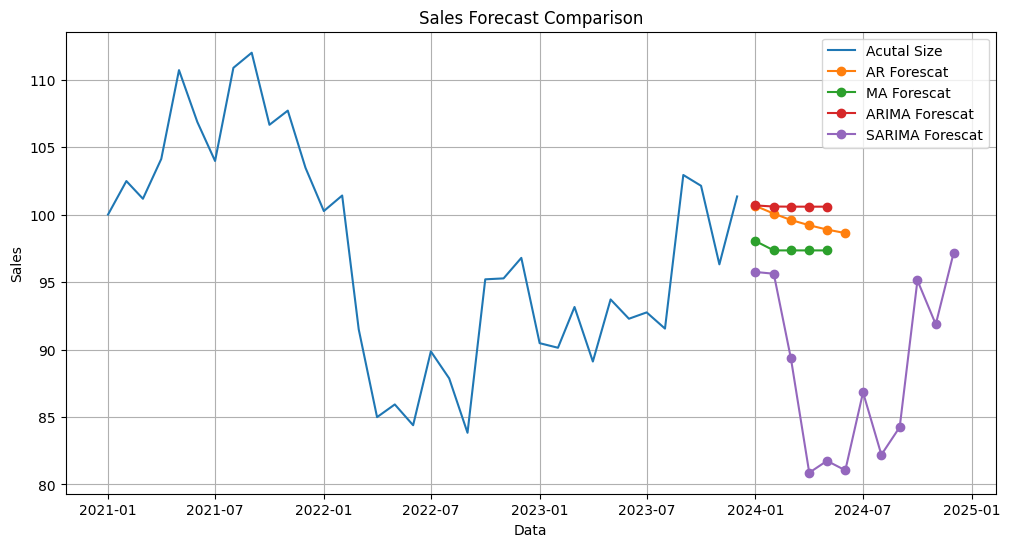

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

#Plot actual sales
plt.plot(df.index,df["Sales"],label="Acutal Size")
#Plot AR forecast 
plt.plot(ar_forecast.index,ar_forecast,
         marker="o", label="AR Forescat")
#Plot MA forecast
plt.plot(ma_forecast.index,ma_forecast,
         marker="o", label="MA Forescat")
#Plot ARIMA forecast
plt.plot(arima_forecast.index,arima_forecast,
         marker="o", label="ARIMA Forescat")
#Plot SARIMA forecast
plt.plot(sarima_forecast.index,sarima_forecast,
         marker="o", label="SARIMA Forescat")


plt.title("Sales Forecast Comparison")
plt.xlabel("Data")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()